# Standard Transformer: train, evaluate, visualize, and generate text

This notebook is self-contained. Run the cells from top to bottom. It trains a small character-level language model on Tiny Shakespeare, plots the learning curves, measures performance, saves checkpoints, and lets you generate text from your own prompts.

**Experiment partner:** run the other notebook with the same settings, then return to the comparison cell at the end.


## Experiment design and how to interpret it

We compare two small causal language models on the **same Tiny Shakespeare character-level dataset**.

- **Standard Transformer:** four independent Transformer blocks.
- **Looped Transformer:** one Transformer block reused four times (the same weights are used at every loop).

Both models use the same tokenizer, train/validation split, context length, embedding width, number of block applications per forward pass, optimizer, batch size, and number of optimizer updates.

**Important:** This first experiment isolates *weight sharing*, not equal parameter count. The standard model has four independently learned blocks, while the looped model has one shared block. Therefore, their parameter counts differ substantially. They perform four block applications per forward pass, but they do not have equal representational capacity. We will report parameters, loss, throughput, and memory rather than assuming one architecture must win.

### What this experiment can and cannot tell us

It can show whether the looped model learns a useful language model under this small setup, and what the parameter-saving / quality / speed trade-off looks like.

It cannot establish that looped Transformers are universally better or worse. Results depend on model size, data, training recipe, loop count, initialization, and compute budget. A rigorous follow-up would add parameter-matched and compute-matched comparisons and repeat each run across multiple random seeds.


## 1. Install / import dependencies

Run this cell first. If your environment is missing packages, install them in a fresh environment, restart the kernel, and then run the import cell. Do not upgrade PyTorch inside an active kernel.


In [1]:
# Install dependencies only in a fresh environment when needed, then restart the kernel.
# %pip install torch matplotlib pandas ipywidgets

In [2]:
# If the imports fail because a package is missing, install it in a fresh environment,
# restart the kernel, and rerun this cell:
# %pip install torch matplotlib pandas ipywidgets

import os
import math
import json
import csv
import random
import time
import urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

print("PyTorch:", torch.__version__)


PyTorch: 2.9.1+cu128


## 2. Select CPU / GPU and set random seeds

In [3]:
# Reproducibility and compute device
SEED = 1337
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("Using device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
elif DEVICE.type == "cpu":
    print("CPU mode: training will be slower. You can reduce MAX_ITERS in the configuration cell.")


Using device: cuda
GPU: NVIDIA GeForce RTX 4070 Laptop GPU


## 3. Configure the experiment

In [4]:
# Experiment configuration — change these values to run a larger/smaller experiment.
BATCH_SIZE = 32
BLOCK_SIZE = 128       # number of previous characters available to predict the next character
MAX_ITERS = 1200       # optimizer updates; try 300 for a quick smoke test
EVAL_INTERVAL = 100
EVAL_ITERS = 20
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-2
GRAD_CLIP = 1.0

D_MODEL = 128
N_HEADS = 4
N_BLOCK_APPLICATIONS = 4  # both architectures apply four Transformer blocks per forward pass
DROPOUT = 0.1

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print({
    "batch_size": BATCH_SIZE,
    "context_length": BLOCK_SIZE,
    "optimizer_steps": MAX_ITERS,
    "embedding_width": D_MODEL,
    "heads": N_HEADS,
    "block_applications": N_BLOCK_APPLICATIONS,
})


{'batch_size': 32, 'context_length': 128, 'optimizer_steps': 1200, 'embedding_width': 128, 'heads': 4, 'block_applications': 4}


## 2. Download and prepare the dataset

We use Tiny Shakespeare, a small public-domain text corpus commonly used for character-level language-model demonstrations. The model predicts the next **character**, not the next word or subword token. This keeps the experiment compact and easy to inspect.

The first run downloads the text and caches it under `data/`. Both notebooks use the exact same URL and preprocessing. If you already have the file, place it at `data/tinyshakespeare.txt` before running this cell.


In [5]:
DATA_PATH = DATA_DIR / "tinyshakespeare.txt"
DATA_URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

if not DATA_PATH.exists():
    print("Downloading Tiny Shakespeare...")
    try:
        urllib.request.urlretrieve(DATA_URL, DATA_PATH)
    except Exception as exc:
        raise RuntimeError(
            "Could not download Tiny Shakespeare. Check your internet connection, "
            "or manually place the text file at data/tinyshakespeare.txt."
        ) from exc

text = DATA_PATH.read_text(encoding="utf-8")
if len(text) < 100_000:
    raise ValueError(f"Dataset looks unexpectedly small ({len(text):,} characters). Check {DATA_PATH}.")

print(f"Dataset characters: {len(text):,}")
print("Preview:\n", text[:500])


Dataset characters: 1,115,394
Preview:
 First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


## 3. Build a character tokenizer and train/validation split

Each distinct character receives an integer ID. We reserve ID `0` for unknown characters so you can try prompts containing characters that were not present in training data.

We split the raw text in order: the first 90% is training text and the final 10% is validation text. The vocabulary is built from the full corpus so validation characters can be represented; this reveals character identities but not validation sequences or targets.


In [6]:
# Character-level vocabulary shared by both architectures
chars = sorted(set(text))
UNK_TOKEN = "<UNK>"
itos = [UNK_TOKEN] + chars
stoi = {ch: i + 1 for i, ch in enumerate(chars)}

vocab_size = len(itos)

def encode(s: str):
    """Convert text to character IDs. Unknown characters map to ID 0."""
    return [stoi.get(ch, 0) for ch in s]

def decode(ids):
    """Convert character IDs back to text; unknown IDs become a replacement marker."""
    return "".join(itos[int(i)] if int(i) < len(itos) else "�" for i in ids).replace(UNK_TOKEN, "�")

split_at = int(0.90 * len(text))
train_ids = torch.tensor(encode(text[:split_at]), dtype=torch.long, device=DEVICE)
val_ids = torch.tensor(encode(text[split_at:]), dtype=torch.long, device=DEVICE)

if len(train_ids) <= BLOCK_SIZE + 1 or len(val_ids) <= BLOCK_SIZE + 1:
    raise ValueError("Dataset split is too small for the chosen BLOCK_SIZE.")

print("Vocabulary size:", vocab_size)
print("Train characters:", len(train_ids))
print("Validation characters:", len(val_ids))
print("Encoded preview:", encode("ROMEO:")[:20])


Vocabulary size: 66
Train characters: 1003854
Validation characters: 111540
Encoded preview: [31, 28, 26, 18, 28, 11]


## 4. Create mini-batches

In [7]:
def get_batch(split: str):
    """Sample random contiguous input/target windows from the selected split."""
    source = train_ids if split == "train" else val_ids
    starts = torch.randint(
        low=0,
        high=len(source) - BLOCK_SIZE - 1,
        size=(BATCH_SIZE,),
        device=DEVICE,
    )
    offsets = torch.arange(BLOCK_SIZE, device=DEVICE)
    x = source[starts[:, None] + offsets[None, :]]
    y = source[starts[:, None] + offsets[None, :] + 1]
    return x, y

xb, yb = get_batch("train")
print("Input batch shape:", tuple(xb.shape))
print("Target batch shape:", tuple(yb.shape))
print("One input example:\n", decode(xb[0].tolist()))
print("One target example:\n", decode(yb[0].tolist()))


Input batch shape: (32, 128)
Target batch shape: (32, 128)
One input example:
  of untimely death.
But He, that hath the steerage of my course,
Direct my sail! On, lusty gentlemen.

BENVOLIO:
Strike, drum.


One target example:
 of untimely death.
But He, that hath the steerage of my course,
Direct my sail! On, lusty gentlemen.

BENVOLIO:
Strike, drum.

F


## 5. Transformer building blocks

The attention layer applies a causal mask, so a position can only use current and previous characters. The MLP transforms each position independently. Residual connections and layer normalization are used in both model variants.

In [8]:
class CausalSelfAttention(nn.Module):
    """Multi-head causal self-attention. Future positions are masked."""
    def __init__(self, d_model: int, n_heads: int, dropout: float):
        super().__init__()
        if d_model % n_heads != 0:
            raise ValueError("d_model must be divisible by n_heads")
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=False)
        self.proj = nn.Linear(d_model, d_model, bias=False)
        self.attn_dropout = dropout
        self.resid_dropout = nn.Dropout(dropout)

    def forward(self, x):
        batch_size, seq_len, d_model = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)

        # [batch, sequence, channels] -> [batch, heads, sequence, head_dim]
        q = q.view(batch_size, seq_len, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(batch_size, seq_len, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(batch_size, seq_len, self.n_heads, self.head_dim).transpose(1, 2)

        if hasattr(F, "scaled_dot_product_attention"):
            out = F.scaled_dot_product_attention(
                q, k, v,
                dropout_p=self.attn_dropout if self.training else 0.0,
                is_causal=True,
            )
        else:
            # Compatibility fallback for older PyTorch versions.
            scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
            causal_mask = torch.tril(torch.ones(seq_len, seq_len, device=x.device, dtype=torch.bool))
            scores = scores.masked_fill(~causal_mask, float("-inf"))
            weights = F.softmax(scores, dim=-1)
            weights = F.dropout(weights, p=self.attn_dropout, training=self.training)
            out = weights @ v

        out = out.transpose(1, 2).contiguous().view(batch_size, seq_len, d_model)
        return self.resid_dropout(self.proj(out))


class FeedForward(nn.Module):
    """Position-wise MLP used after attention."""
    def __init__(self, d_model: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Linear(4 * d_model, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    """Pre-layer-normalized Transformer block with residual connections."""
    def __init__(self, d_model: int, n_heads: int, dropout: float):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = FeedForward(d_model, dropout)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x


## 6. Define the model

The `ModuleList` below contains four independently parameterized Transformer blocks. Each block has its own attention and MLP weights.

In [9]:
class StandardTransformerLM(nn.Module):
    """A conventional Transformer with independent parameters in every block."""
    def __init__(self, vocab_size, d_model, n_heads, n_layers, dropout, max_seq_len):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.position_embedding = nn.Embedding(max_seq_len, d_model)
        self.blocks = nn.ModuleList([
            TransformerBlock(d_model, n_heads, dropout)
            for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, targets=None):
        batch_size, seq_len = input_ids.shape
        if seq_len > self.position_embedding.num_embeddings:
            raise ValueError("Sequence is longer than the configured maximum context")
        positions = torch.arange(seq_len, device=input_ids.device)
        x = self.token_embedding(input_ids) + self.position_embedding(positions)[None, :, :]
        for block in self.blocks:
            x = block(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))
        return logits, loss


model = StandardTransformerLM(
    vocab_size=vocab_size,
    d_model=D_MODEL,
    n_heads=N_HEADS,
    n_layers=N_BLOCK_APPLICATIONS,
    dropout=DROPOUT,
    max_seq_len=BLOCK_SIZE,
).to(DEVICE)

MODEL_NAME = "standard"
MODEL_LABEL = "Standard Transformer"
print(model)


StandardTransformerLM(
  (token_embedding): Embedding(66, 128)
  (position_embedding): Embedding(128, 128)
  (blocks): ModuleList(
    (0-3): 4 x TransformerBlock(
      (ln1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (attn): CausalSelfAttention(
        (qkv): Linear(in_features=128, out_features=384, bias=False)
        (proj): Linear(in_features=128, out_features=128, bias=False)
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
      (ln2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (mlp): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=128, out_features=512, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=512, out_features=128, bias=True)
          (3): Dropout(p=0.1, inplace=False)
        )
      )
    )
  )
  (final_norm): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
  (lm_head): Linear(in_features=128, out_features=66, bias=False)
)


## 7. Inspect model size

In [10]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

n_params = count_parameters(model)
param_size_mb_fp32 = n_params * 4 / (1024 ** 2)  # parameter storage only, assuming float32

print(f"Model: {MODEL_LABEL}")
print(f"Trainable parameters: {n_params:,}")
print(f"Approx. FP32 parameter storage: {param_size_mb_fp32:.2f} MiB")
print(f"Block applications per forward pass: {N_BLOCK_APPLICATIONS}")


Model: Standard Transformer
Trainable parameters: 824,576
Approx. FP32 parameter storage: 3.15 MiB
Block applications per forward pass: 4


## 5. Train the model

We use AdamW and next-character prediction. At each position, the model predicts the character immediately to its right. The training loss is cross-entropy.

The validation batches are sampled from held-out text. Validation loss is an estimate of how well the model predicts unseen portions of this corpus. Perplexity is `exp(loss)`; lower is better, but compare it only under the same tokenizer and evaluation setup.


In [11]:
@torch.no_grad()
def estimate_loss(model, eval_iters=EVAL_ITERS):
    model.eval()
    results = {}
    for split in ("train", "val"):
        losses = []
        for _ in range(eval_iters):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses.append(loss.item())
        results[split] = float(np.mean(losses))
    model.train()
    return results


def sync_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elif DEVICE.type == "mps" and hasattr(torch, "mps"):
        torch.mps.synchronize()


# Re-seed immediately before training for reproducible batch sampling between notebook runs.
torch.manual_seed(SEED)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

if DEVICE.type == "cuda":
    torch.cuda.reset_peak_memory_stats()

history = {"step": [], "train_loss": [], "val_loss": []}
sync_device()
train_start = time.perf_counter()

# Initial evaluation before the first optimizer update.
initial = estimate_loss(model)
history["step"].append(0)
history["train_loss"].append(initial["train"])
history["val_loss"].append(initial["val"])
print(f"step     0 | train {initial['train']:.4f} | val {initial['val']:.4f}")

for step in range(1, MAX_ITERS + 1):
    model.train()
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
    optimizer.step()

    if step % EVAL_INTERVAL == 0 or step == MAX_ITERS:
        metrics = estimate_loss(model)
        history["step"].append(step)
        history["train_loss"].append(metrics["train"])
        history["val_loss"].append(metrics["val"])
        print(f"step {step:5d} | train {metrics['train']:.4f} | val {metrics['val']:.4f}")

sync_device()
training_seconds = time.perf_counter() - train_start
final_train_loss = history["train_loss"][-1]
final_val_loss = history["val_loss"][-1]

print(f"\nTraining time: {training_seconds:.1f} seconds")
print(f"Final train loss: {final_train_loss:.4f}")
print(f"Final validation loss: {final_val_loss:.4f}")
print(f"Final validation perplexity: {math.exp(min(final_val_loss, 20)):.2f}")


step     0 | train 4.2134 | val 4.2131


step   100 | train 2.6012 | val 2.6052


step   200 | train 2.4788 | val 2.4856


step   300 | train 2.4154 | val 2.4304


step   400 | train 2.3531 | val 2.3582


step   500 | train 2.2860 | val 2.3134


... (3 outputs left out)

step   900 | train 2.0379 | val 2.0904


step  1000 | train 1.9862 | val 2.0384


step  1100 | train 1.9309 | val 2.0080


step  1200 | train 1.8751 | val 1.9712

Training time: 21.9 seconds
Final train loss: 1.8751
Final validation loss: 1.9712
Final validation perplexity: 7.18


## 8. Visualize training and validation loss

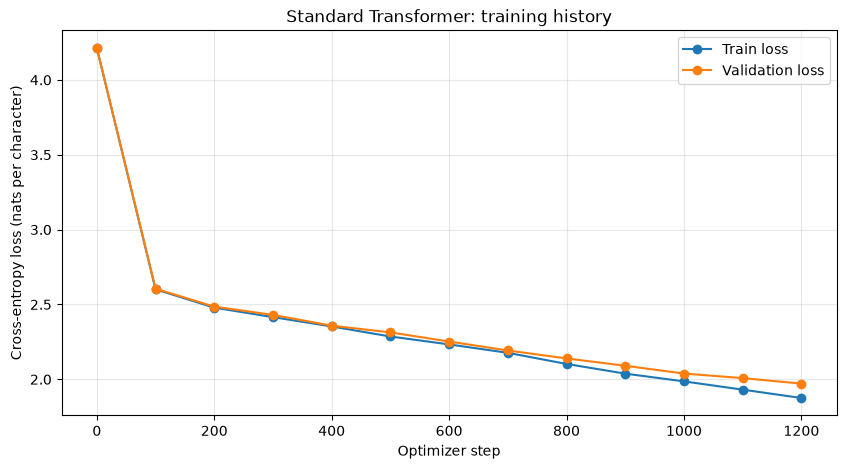

,step,train_loss,val_loss
0,0,4.213355,4.213074
1,100,2.601168,2.605248
2,200,2.478804,2.485593
3,300,2.415369,2.430417
4,400,2.353115,2.358209


In [12]:
# Plot training and validation loss
history_df = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(history_df["step"], history_df["train_loss"], marker="o", label="Train loss")
ax.plot(history_df["step"], history_df["val_loss"], marker="o", label="Validation loss")
ax.set_title(f"{MODEL_LABEL}: training history")
ax.set_xlabel("Optimizer step")
ax.set_ylabel("Cross-entropy loss (nats per character)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

history_df.head()


## 9. Generate an initial sample

In [13]:
@torch.no_grad()
def generate_text(model, prompt, max_new_tokens=300, temperature=0.8, top_k=40):
    """Autoregressively generate characters from a text prompt."""
    if temperature <= 0:
        raise ValueError("temperature must be greater than zero")
    model.eval()
    prompt_ids = encode(prompt)
    if not prompt_ids:
        prompt_ids = [0]  # start from the unknown token if prompt is empty
    idx = torch.tensor([prompt_ids], dtype=torch.long, device=DEVICE)

    for _ in range(max_new_tokens):
        idx_cond = idx[:, -BLOCK_SIZE:]
        logits, _ = model(idx_cond)
        logits = logits[:, -1, :] / temperature

        if top_k is not None:
            k = min(int(top_k), logits.size(-1))
            values, _ = torch.topk(logits, k)
            logits[logits < values[:, [-1]]] = float("-inf")

        probs = F.softmax(logits, dim=-1)
        next_id = torch.multinomial(probs, num_samples=1)
        idx = torch.cat((idx, next_id), dim=1)

    return decode(idx[0].tolist())


# First sample. Change the prompt and settings in the next cell to experiment yourself.
print(generate_text(
    model,
    prompt="ROMEO:",
    max_new_tokens=500,
    temperature=0.8,
    top_k=40,
))


ROMEO:
Whage maden's a was a com mistion the sting,
This ime thou and facest and band oll the me.

LOUS:
Ad, not a and blood that with with, ward with bre's and the gel my lave
My come fulll oime crif gatile hey a ond to to their my ene:
What heave not and that mand the theouse.

DUCETERYTHUS:
by sear groodss that combst ow a and mone
Thous your that!

Firncese in the with ot you have theur statinZens:
I refer the fat is him thou martt of the hinst
As your nevant pauliing all of I eto and no and roumb


## 8. Experiment with your own prompts

Edit `MY_PROMPT`, `MAX_NEW_TOKENS`, `TEMPERATURE`, and `TOP_K`, then run the cell again.

- **Temperature**: lower values make sampling more conservative; higher values increase randomness.
- **Top-k**: restricts each next-character sample to the `k` highest-scoring characters. Set it to `None` to disable top-k filtering.
- **Prompt**: try `ROMEO:`, `JULIET:`, `KING LEAR:`, or your own text. This is a character-level Shakespeare model, so do not expect reliable modern factual answers.


In [14]:
MY_PROMPT = "JULIET:"
MAX_NEW_TOKENS = 600
TEMPERATURE = 0.8
TOP_K = 40  # set to None to disable top-k filtering

print(generate_text(
    model,
    prompt=MY_PROMPT,
    max_new_tokens=MAX_NEW_TOKENS,
    temperature=TEMPERATURE,
    top_k=TOP_K,
))


JULIET:
If an Carving hing, would stink the hold shomer in homs.
Senad this so that the be herew hip if are
To you but your poul tho their not too the notheg
bet the nake the his live;
The hat ut tis sampest in hing, from faish,
The  heave has o'd the him cous beis your of Eath,
He march then teme is a barfoin ster;
And the you wounighth lombe any in kper' withh and
that to dill and bading of to sjonttleque,
Yen to far words'd that may a hifes,
Ko, with be not upped broth shim:
Whing yous pome's as her have wand shish a oum.

CORIUTOLIO:
I cow she shich morgen, your wray nour,
The sent the is meak, a


### Optional: interactive generation controls

In [15]:
# Optional interactive prompt controls (works in Jupyter when ipywidgets is installed).
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output

    prompt_widget = widgets.Textarea(
        value="ROMEO:", description="Prompt:", layout=widgets.Layout(width="95%", height="80px")
    )
    length_widget = widgets.IntSlider(value=300, min=50, max=1000, step=50, description="New chars:")
    temp_widget = widgets.FloatSlider(value=0.8, min=0.2, max=1.5, step=0.1, description="Temperature:")
    topk_widget = widgets.IntSlider(value=40, min=1, max=min(100, vocab_size), step=1, description="Top-k:")
    generate_button = widgets.Button(description="Generate text", button_style="success")
    output_widget = widgets.Output()

    def _on_generate_clicked(_):
        with output_widget:
            clear_output(wait=True)
            print(generate_text(
                model,
                prompt=prompt_widget.value,
                max_new_tokens=length_widget.value,
                temperature=temp_widget.value,
                top_k=topk_widget.value,
            ))

    generate_button.on_click(_on_generate_clicked)
    display(prompt_widget, length_widget, temp_widget, topk_widget, generate_button, output_widget)
except ImportError:
    print("ipywidgets is not installed. Use the editable MY_PROMPT cell above instead.")


Textarea(value='ROMEO:', description='Prompt:', layout=Layout(height='80px', width='95%'))

IntSlider(value=300, description='New chars:', max=1000, min=50, step=50)

FloatSlider(value=0.8, description='Temperature:', max=1.5, min=0.2)

IntSlider(value=40, description='Top-k:', max=66, min=1)

Button(button_style='success', description='Generate text', style=ButtonStyle())

Output()

## 10. Measure performance and save artifacts

We measure a batch-1 forward pass on a full context window and autoregressive generation of 60 characters. Generation repeatedly runs the model without a KV cache, which keeps this implementation simple and the comparison symmetric. Timings depend on hardware and can be noisy. CUDA peak memory is reported only when running on an NVIDIA GPU.

In [16]:
# Measure forward-pass latency at batch size 1 and the configured context length.
@torch.no_grad()
def benchmark_forward(model, warmup=5, repeats=30):
    model.eval()
    sample = torch.randint(0, vocab_size, (1, BLOCK_SIZE), device=DEVICE)
    for _ in range(warmup):
        model(sample)
    sync_device()
    start = time.perf_counter()
    for _ in range(repeats):
        model(sample)
    sync_device()
    elapsed = time.perf_counter() - start
    return 1000 * elapsed / repeats


@torch.no_grad()
def benchmark_generation(model, prompt="ROMEO:", new_tokens=60):
    sync_device()
    start = time.perf_counter()
    _ = generate_text(model, prompt, max_new_tokens=new_tokens, temperature=0.8, top_k=40)
    sync_device()
    elapsed = time.perf_counter() - start
    return elapsed, new_tokens / max(elapsed, 1e-9)

forward_ms = benchmark_forward(model)
generation_seconds, generation_chars_per_sec = benchmark_generation(model)
peak_cuda_memory_mib = None
if DEVICE.type == "cuda":
    peak_cuda_memory_mib = torch.cuda.max_memory_allocated() / (1024 ** 2)

training_chars = MAX_ITERS * BATCH_SIZE * BLOCK_SIZE
training_chars_per_sec = training_chars / max(training_seconds, 1e-9)

performance = {
    "model_name": MODEL_NAME,
    "model_label": MODEL_LABEL,
    "seed": SEED,
    "vocab_size": vocab_size,
    "parameters": n_params,
    "parameter_storage_fp32_mib": param_size_mb_fp32,
    "block_applications_per_forward": N_BLOCK_APPLICATIONS,
    "optimizer_steps": MAX_ITERS,
    "batch_size": BATCH_SIZE,
    "context_length": BLOCK_SIZE,
    "training_seconds_including_periodic_eval": training_seconds,
    "approx_training_characters_per_second": training_chars_per_sec,
    "final_train_loss": final_train_loss,
    "final_validation_loss": final_val_loss,
    "final_validation_perplexity": math.exp(min(final_val_loss, 20)),
    "forward_latency_ms_batch1_context": forward_ms,
    "generation_seconds_for_60_chars": generation_seconds,
    "generation_chars_per_second": generation_chars_per_sec,
    "peak_cuda_memory_mib": peak_cuda_memory_mib,
    "device": str(DEVICE),
}

print(pd.Series(performance).to_string())


model_name                                              standard
model_label                                 Standard Transformer
seed                                                        1337
vocab_size                                                    66
parameters                                                824576
parameter_storage_fp32_mib                              3.145508
block_applications_per_forward                                 4
optimizer_steps                                             1200
batch_size                                                    32
context_length                                               128
training_seconds_including_periodic_eval               21.922697
approx_training_characters_per_second              224205.994805
final_train_loss                                        1.875137
final_validation_loss                                   1.971153
final_validation_perplexity                             7.178951
forward_latency_ms_batch1

In [17]:
# Save loss history, metrics, and model weights so the two notebooks can be compared.
history_path = RESULTS_DIR / "standard_history.csv"
metrics_path = RESULTS_DIR / "standard_metrics.json"
checkpoint_path = RESULTS_DIR / "standard_model.pt"

history_df.to_csv(history_path, index=False)
metrics_path.write_text(json.dumps(performance, indent=2), encoding="utf-8")
torch.save({
    "model_state_dict": model.state_dict(),
    "model_name": MODEL_NAME,
    "model_config": {
        "vocab_size": vocab_size,
        "d_model": D_MODEL,
        "n_heads": N_HEADS,
        "block_applications": N_BLOCK_APPLICATIONS,
        "dropout": DROPOUT,
        "block_size": BLOCK_SIZE,
    },
    "itos": itos,
    "stoi": stoi,
}, checkpoint_path)

print("Saved:")
print(" -", history_path)
print(" -", metrics_path)
print(" -", checkpoint_path)


Saved:
 - results\standard_history.csv
 - results\standard_metrics.json
 - results\standard_model.pt


### Visual summary of this model

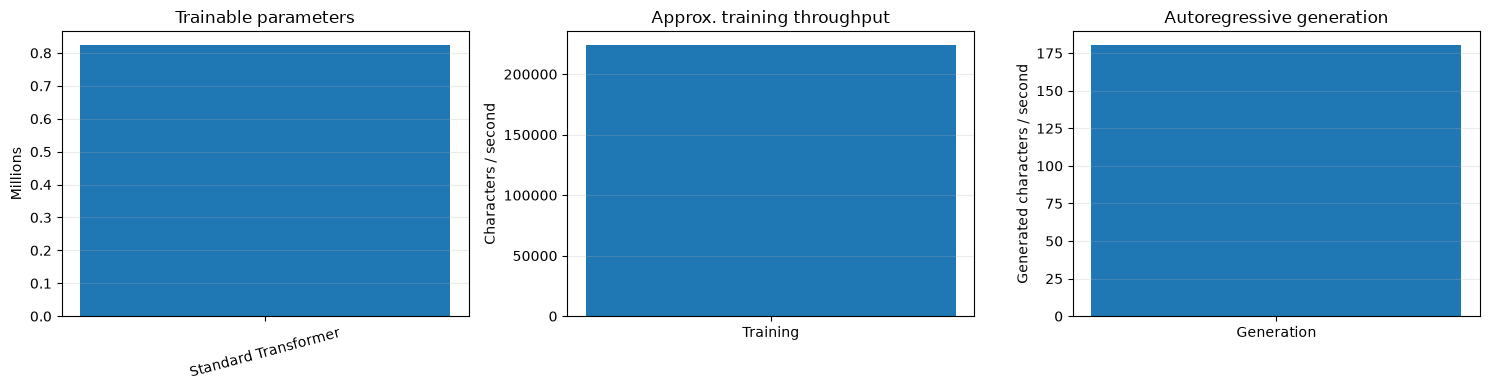

In [18]:
# Visualize the single-model performance profile.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar([MODEL_LABEL], [performance["parameters"] / 1e6])
axes[0].set_title("Trainable parameters")
axes[0].set_ylabel("Millions")
axes[0].tick_params(axis="x", rotation=15)

axes[1].bar(["Training"], [performance["approx_training_characters_per_second"]])
axes[1].set_title("Approx. training throughput")
axes[1].set_ylabel("Characters / second")

axes[2].bar(["Generation"], [performance["generation_chars_per_second"]])
axes[2].set_title("Autoregressive generation")
axes[2].set_ylabel("Generated characters / second")

for ax in axes:
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


## 11. Compare both notebooks

Run both notebooks from the **same working directory**. Each writes its metrics and loss history into `results/`. After both have finished, run this cell in either notebook to compare them.

The comparison reads saved result files; it does not retrain either model.


In [19]:
standard_metrics_path = RESULTS_DIR / "standard_metrics.json"
looped_metrics_path = RESULTS_DIR / "looped_metrics.json"

if standard_metrics_path.exists() and looped_metrics_path.exists():
    standard_metrics = json.loads(standard_metrics_path.read_text(encoding="utf-8"))
    looped_metrics = json.loads(looped_metrics_path.read_text(encoding="utf-8"))
    comparison = pd.DataFrame([standard_metrics, looped_metrics]).set_index("model_label")
    display(comparison[[
        "parameters",
        "final_validation_loss",
        "final_validation_perplexity",
        "training_seconds_including_periodic_eval",
        "approx_training_characters_per_second",
        "forward_latency_ms_batch1_context",
        "generation_chars_per_second",
        "peak_cuda_memory_mib",
    ]])

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    labels = ["Standard", "Looped"]
    axes[0].bar(labels, [standard_metrics["parameters"] / 1e6, looped_metrics["parameters"] / 1e6])
    axes[0].set_title("Trainable parameters (millions)")
    axes[1].bar(labels, [standard_metrics["final_validation_loss"], looped_metrics["final_validation_loss"]])
    axes[1].set_title("Final validation loss (lower is better)")
    axes[2].bar(labels, [standard_metrics["forward_latency_ms_batch1_context"], looped_metrics["forward_latency_ms_batch1_context"]])
    axes[2].set_title("Forward latency in ms (lower is faster)")
    for ax in axes:
        ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

    # Overlay both training curves if both CSVs are available.
    std_hist_path = RESULTS_DIR / "standard_history.csv"
    loop_hist_path = RESULTS_DIR / "looped_history.csv"
    if std_hist_path.exists() and loop_hist_path.exists():
        std_hist = pd.read_csv(std_hist_path)
        loop_hist = pd.read_csv(loop_hist_path)
        plt.figure(figsize=(10, 5))
        plt.plot(std_hist["step"], std_hist["val_loss"], marker="o", label="Standard validation")
        plt.plot(loop_hist["step"], loop_hist["val_loss"], marker="o", label="Looped validation")
        plt.xlabel("Optimizer step")
        plt.ylabel("Validation cross-entropy")
        plt.title("Validation learning curves")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.show()
else:
    missing = [str(p) for p in (standard_metrics_path, looped_metrics_path) if not p.exists()]
    print("Run both notebooks first. Missing result file(s):")
    for path in missing:
        print(" -", path)


Run both notebooks first. Missing result file(s):
 - results\looped_metrics.json


## 12. Analysis questions

After both runs, answer these questions from your actual results:

1. Which model has lower validation loss? By how much?
2. How many fewer parameters does the looped model use?
3. Is the looped model faster or slower per forward pass on your device?
4. Does lower training loss also correspond to lower validation loss, or is there overfitting?
5. Do the generated samples look different? Are they coherent for several lines, or do they collapse into repetitive text?
6. Is the parameter saving worth the loss in quality (if there is one)?

### Important next experiment

This comparison has four block applications in each forward pass, but it is **not parameter-matched**. For a stronger study, run at least three seeds and add a parameter-matched standard model (for example, a narrower or shallower standard Transformer) and a compute-matched study. Also keep the tokenizer and dataset fixed. Do not conclude that one architecture is generally superior from one small run.
